In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.linear_model import LinearRegression

%matplotlib inline

In [2]:
df = pd.read_csv('datasets/Advertising.csv')
df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [3]:
df.drop(columns='Unnamed: 0', inplace=True)

In [5]:
df.dtypes

TV           float64
radio        float64
newspaper    float64
sales        float64
dtype: object

In [4]:
df.isnull().sum()

TV           0
radio        0
newspaper    0
sales        0
dtype: int64

In [34]:
features = ['TV', 'radio', 'newspaper']
X = df[features]
y = df['sales']

In [35]:
lr = LinearRegression()
lr.fit(X, y)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None,
         normalize=False)

In [36]:
predictions = lr.predict(X)

In [37]:
residuals = y - predictions

In [38]:
residuals.mean()

-1.092459456231154e-15

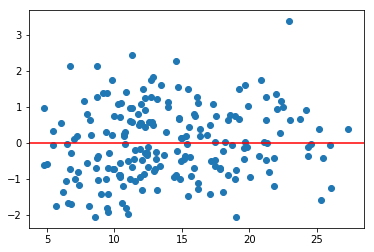

In [33]:
plt.scatter(predictions, np.random.randn(len(predictions)))
plt.axhline(0, color='r')

- Heteroscedasticity: Power transformation
- Curves in the scatterplot: Polynomial features
- Outliers: Remove them

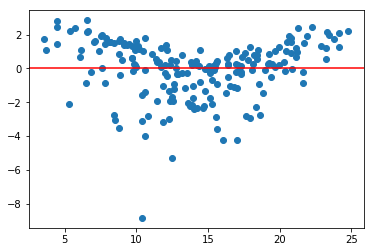

In [39]:
plt.scatter(predictions, residuals)
plt.axhline(0, color='r')

In [40]:
np.abs(residuals).mean()

1.2520112296870685

In [41]:
metrics.mean_absolute_error(y, predictions)

1.2520112296870682

## RSS

In [47]:
rss = (residuals ** 2).sum()

## MSE

In [48]:
rss / len(residuals)

2.784126314510936

In [45]:
metrics.mean_squared_error(y, predictions)

2.784126314510936

## RMSE

In [49]:
np.sqrt(metrics.mean_squared_error(y, predictions))

1.6685701407225697

## R2

In [52]:
null_prediction = y.mean()

null_residuals = y - null_prediction

null_ss = (null_residuals ** 2).sum()

In [54]:
1 - rss / null_ss

0.8972106381789522

In [50]:
metrics.r2_score(y, predictions)

0.8972106381789522

In [55]:
lr.score(X, y)

0.8972106381789521